<a href="https://colab.research.google.com/github/annaizyurieva-stack/IDP-Project-Diabetics/blob/3-%D1%8D%D1%82%D0%B0%D0%BF/3_%D1%8D%D1%82%D0%B0%D0%BF_%D1%87%D0%B0%D1%81%D1%82%D1%8C_2_%D0%BF%D1%80%D0%B5%D0%B4%D0%BE%D0%B1%D1%80%D0%B0%D0%B1%D0%BE%D1%82%D0%BA%D0%B0_%D0%98%D0%B7%D1%8E%D1%80%D1%8C%D0%B5%D0%B2%D0%B0.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Этап 3. Часть 2 — Предобработка данных

**Датасет:** `diabetes_clean.csv` (результат этапа 2): 768 пациенток, 8 числовых признаков, 2 бинарных флага пропусков и цель `Outcome`.

**План (по заданию)**
1. Разделить выборку на train и test (80/20) — **до** любых преобразований, чтобы не было утечки данных.
2. Выбрать один числовой признак и применить к нему несколько методов масштабирования.
3. Построить графики распределения до и после каждого преобразования.
4. Сделать вывод о различиях методов и выбрать лучший для этого признака.
5. Предобработать все остальные столбцы с обоснованием метода для каждого.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import skew

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, MinMaxScaler, MaxAbsScaler, RobustScaler, FunctionTransformer
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

sns.set_theme(style="whitegrid")
pd.set_option("display.width", 140)
pd.set_option("display.max_columns", 30)

TARGET = "Outcome"
RANDOM_STATE = 42

## 0. Загрузка данных

In [2]:
try:
    from google.colab import files
    uploaded = files.upload()            # загружаем diabetes_clean.csv
    DATA_PATH = list(uploaded.keys())[0]
except ImportError:
    DATA_PATH = "diabetes_clean.csv"     # локальный запуск

df = pd.read_csv(DATA_PATH)
print("Строк:", df.shape[0], "| Столбцов:", df.shape[1])
print("Пропусков:", int(df.isna().sum().sum()))
df.dtypes.to_frame("тип")

Saving diabetes_clean.csv to diabetes_clean.csv
Строк: 768 | Столбцов: 11
Пропусков: 0


,тип
Pregnancies,int64
Glucose,float64
BloodPressure,float64
SkinThickness,float64
Insulin,float64
BMI,float64
DiabetesPedigreeFunction,float64
Age,int64
Outcome,int64
Insulin_was_missing,int64


## 1. Разделение на train и test (80/20)

Делим сразу, до подбора каких-либо параметров. Все «обучаемые» преобразования (среднее, стандартное отклонение, квартили, минимум и максимум) считаются **только по train**, а на test применяются те же параметры. Иначе информация из test «протекла» бы в обучение. `stratify=y` сохраняет долю больных (≈35%) в обеих частях, потому что классы не сбалансированы.

In [3]:
X = df.drop(columns=TARGET)
y = df[TARGET]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE, stratify=y)

print("train:", X_train.shape, "| test:", X_test.shape)
print(f"Доля больных: train {y_train.mean():.1%} | test {y_test.mean():.1%}")

train: (614, 10) | test: (154, 10)
Доля больных: train 34.9% | test 35.1%


## 2. Масштабирование одного признака

### 2.1 Выбор признака
Берём **`DiabetesPedigreeFunction`** (наследственная предрасположенность). Причины:
- сильно скошен вправо (асимметрия ≈ 1.8) и имеет длинный хвост до 2.4 — на этапе 2 по IQR у него найдено больше всего выбросов (29 штук, 3.8%);
- это реально измеренные значения: в отличие от `Insulin` и `SkinThickness` их не заполняли медианой, поэтому график показывает свойства самих данных, а не последствия импутации.

Методы: `StandardScaler`, `MinMaxScaler`, `MaxAbsScaler`, `RobustScaler`, а также пятый вариант — `log1p` + `StandardScaler`, так как масштабирование не меняет форму распределения, а логарифм меняет (см. лекцию про асимметрию). Все параметры подбираем на train.

In [4]:
FEAT = "DiabetesPedigreeFunction"
v_train = X_train[[FEAT]]

print(f"Признак {FEAT}, train: n = {len(v_train)}")
v_train[FEAT].describe().round(3).to_frame().T

Признак DiabetesPedigreeFunction, train: n = 614


,count,mean,std,min,25%,50%,75%,max
DiabetesPedigreeFunction,614.0,0.477,0.33,0.084,0.245,0.382,0.639,2.329


### 2.2 Применение методов

In [5]:
log_std = Pipeline([("log1p", FunctionTransformer(np.log1p)), ("std", StandardScaler())])

methods = {
    "Исходный":              None,
    "StandardScaler":        StandardScaler(),
    "MinMaxScaler":          MinMaxScaler(),
    "MaxAbsScaler":          MaxAbsScaler(),
    "RobustScaler":          RobustScaler(),
    "log1p + StandardScaler": log_std,
}

transformed = {}
for name, sc in methods.items():
    transformed[name] = v_train[FEAT].to_numpy() if sc is None else sc.fit_transform(v_train).ravel()

def describe(a):
    a = np.asarray(a)
    q1, q3 = np.percentile(a, [25, 75])
    z = (a - a.mean()) / a.std()
    return pd.Series({"min": a.min(), "max": a.max(), "среднее": a.mean(), "медиана": np.median(a),
                      "std": a.std(), "IQR": q3 - q1, "асимметрия": skew(a), "значений |z|>3": int((np.abs(z) > 3).sum())})

stats_tbl = pd.DataFrame({k: describe(v) for k, v in transformed.items()}).T
stats_tbl.round(2)

,min,max,среднее,медиана,std,IQR,асимметрия,значений |z|>3
Исходный,0.08,2.33,0.48,0.38,0.33,0.39,1.81,8.0
StandardScaler,-1.19,5.61,-0.00,-0.29,1.00,1.19,1.81,8.0
MinMaxScaler,0.00,1.00,0.18,0.13,0.15,0.18,1.81,8.0
MaxAbsScaler,0.04,1.00,0.20,0.16,0.14,0.17,1.81,8.0
RobustScaler,-0.76,4.94,0.24,0.00,0.84,1.00,1.81,8.0
log1p + StandardScaler,-1.45,4.20,0.00,-0.23,1.00,1.39,1.06,7.0


### 2.3 Графики распределения до и после (гистограмма и boxplot, train)

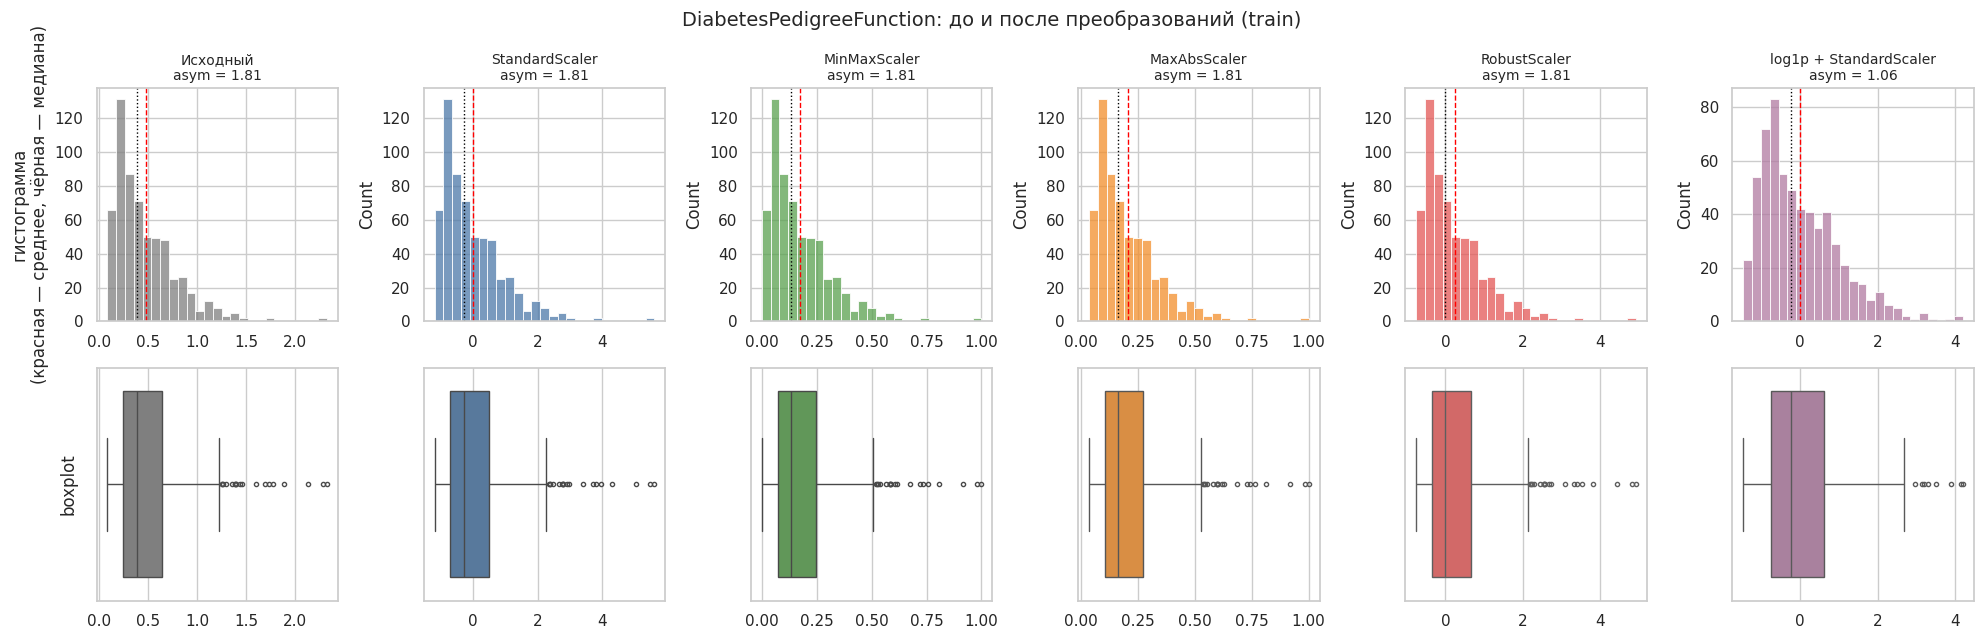

In [6]:
fig, axes = plt.subplots(2, len(transformed), figsize=(20, 6.5))
colors = ["#7F7F7F", "#4C78A8", "#59A14F", "#F28E2B", "#E45756", "#B07AA1"]
for j, ((name, a), c) in enumerate(zip(transformed.items(), colors)):
    sns.histplot(a, bins=25, color=c, ax=axes[0, j])
    axes[0, j].axvline(np.mean(a), color="red", ls="--", lw=1)
    axes[0, j].axvline(np.median(a), color="black", ls=":", lw=1)
    axes[0, j].set_title(f"{name}\nasym = {skew(a):.2f}", fontsize=10)
    sns.boxplot(x=a, color=c, ax=axes[1, j], fliersize=3)
axes[0, 0].set_ylabel("гистограмма\n(красная — среднее, чёрная — медиана)")
axes[1, 0].set_ylabel("boxplot")
plt.suptitle(f"{FEAT}: до и после преобразований (train)", fontsize=14)
plt.tight_layout(); plt.show()

Чтобы увидеть, как каждый метод «размещает» данные на числовой оси, нарисуем все варианты на одном графике (серая полоса — диапазон от −1 до 1).

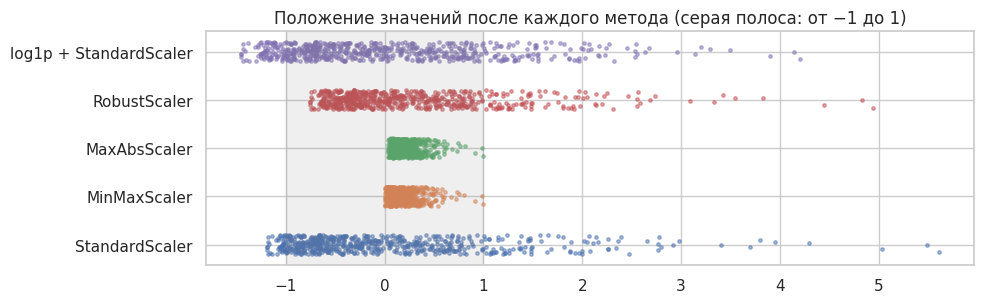

In [7]:
fig, ax = plt.subplots(figsize=(10, 3.2))
for i, (name, a) in enumerate(list(transformed.items())[1:]):
    a = np.asarray(a)
    ax.scatter(a, np.full_like(a, i, dtype=float) + np.random.RandomState(0).uniform(-0.2, 0.2, len(a)), s=6, alpha=0.5)
ax.set_yticks(range(len(transformed) - 1)); ax.set_yticklabels(list(transformed)[1:])
ax.axvspan(-1, 1, color="grey", alpha=0.12)
ax.set_title("Положение значений после каждого метода (серая полоса: от −1 до 1)")
plt.tight_layout(); plt.show()

### 2.4 Вывод по масштабированию

**Что общего.** Первые четыре метода — это линейные преобразования (сдвиг и растяжение). Поэтому форма распределения у них одна и та же: асимметрия везде ≈ 1.81, одинаковое число выбросов (по правилу |z| > 3 их 8 из 614), хвост никуда не исчезает. Это ровно то, о чём говорит лекция: *масштабирование не удаляет выбросы, меняются координаты, а не наблюдения.*

**Чем различаются.**
- `MinMaxScaler` переводит данные в [0, 1], но один максимум (≈2.4) определяет всю шкалу: основная масса значений (среднее ≈ 0.18, std ≈ 0.15) оказывается сжатой в нижней части отрезка. Самый чувствительный к выбросам метод.
- `MaxAbsScaler` делит на максимум по модулю: диапазон [0.04, 1]. Поведение почти такое же, как у MinMax, только без сдвига. Его сильная сторона — разреженные матрицы, а у нас таких нет.
- `StandardScaler` даёт среднее 0 и std 1, но среднее и std сами «подтянуты» хвостом: максимум уходит к 5.6, а минимум всего −1.2 (диапазон несимметричный).
- `RobustScaler` центрирует по медиане (она становится 0) и делит на IQR, поэтому «тело» распределения масштабируется независимо от выбросов (std ≈ 0.84, максимум 4.9). Выбросы остаются выбросами, но не искажают масштаб остальных значений.
- `log1p + StandardScaler` — единственный из вариантов, который меняет форму: асимметрия падает с 1.81 до 1.06, максимум с 5.6 до 4.2, число значений с |z| > 3 с 8 до 7, хвост заметно короче.

**Что выбрать.**
- Среди четырёх «чистых» масштабирований лучше всего подходит **`RobustScaler`**: признак скошен и содержит выбросы, а метод опирается на медиану и IQR. `MinMaxScaler` и `MaxAbsScaler` для него хуже всего.
- Но сам по себе ни один из них не решает проблему асимметрии. **Наилучший итоговый вариант для этого признака: `log1p`, затем `StandardScaler`**: логарифм сжимает хвост, а после него среднее и std уже не так искажены, поэтому можно использовать стандартизацию, удобную для логистической регрессии и kNN/SVM (модели, которые мы планировали в этапе 1). Для деревьев решений масштабирование не требуется вообще, у них важен только порядок значений.

## 3. Предобработка остальных столбцов

В таблице нет категориальных и текстовых признаков (все признаки числовые, `Outcome` уже закодирован как 0/1), поэтому One-Hot, Ordinal, LabelEncoder и TF-IDF здесь не нужны. Остаётся выбрать метод для числовых признаков.

**Правило выбора** (по асимметрии на train):
- асимметрия > 1 (сильный правый хвост): `log1p` → `StandardScaler`;
- асимметрия ≤ 1: `StandardScaler` (форма близка к симметричной, выбросы умеренные);
- бинарные флаги `*_was_missing`: оставляем как есть (0/1 и так в одном масштабе; масштабирование только испортило бы интерпретацию);
- целевая переменная `Outcome`: не преобразуем.

In [8]:
skews = X_train.apply(skew).round(2)

plan = []
for col in X_train.columns:
    if col.endswith("_was_missing"):
        plan.append((col, skews[col], "без изменений", "бинарный флаг 0/1"))
    elif skews[col] > 1:
        plan.append((col, skews[col], "log1p + StandardScaler", "сильный правый хвост (асимметрия > 1)"))
    else:
        plan.append((col, skews[col], "StandardScaler", "форма близка к симметричной"))

plan_df = pd.DataFrame(plan, columns=["признак", "асимметрия (train)", "метод", "причина"]).set_index("признак")
plan_df

,асимметрия (train),метод,причина
признак,,,
Pregnancies,0.88,StandardScaler,форма близка к симметричной
Glucose,0.56,StandardScaler,форма близка к симметричной
BloodPressure,0.36,StandardScaler,форма близка к симметричной
SkinThickness,0.88,StandardScaler,форма близка к симметричной
Insulin,3.07,log1p + StandardScaler,сильный правый хвост (асимметрия > 1)
BMI,0.57,StandardScaler,форма близка к симметричной
DiabetesPedigreeFunction,1.81,log1p + StandardScaler,сильный правый хвост (асимметрия > 1)
Age,1.13,log1p + StandardScaler,сильный правый хвост (асимметрия > 1)
Insulin_was_missing,0.11,без изменений,бинарный флаг 0/1


### Обоснование по признакам

| Признак | Метод | Почему |
|---|---|---|
| `Glucose`, `BloodPressure`, `BMI` | StandardScaler | Почти симметричны (асимметрия 0.4–0.6), сильных выбросов нет. Для линейной модели и kNN нужен единый масштаб, а стандартизация сохраняет форму. |
| `SkinThickness` | StandardScaler | Асимметрия 0.9 (<1), единственный заметный выброс 99 мм признан на этапе 2 допустимым. `RobustScaler` здесь не подходит: из-за заполнения медианой IQR очень узкий (≈ 7 мм), и выброс уходит за значение 10. |
| `Pregnancies` | StandardScaler | Счётный признак с асимметрией 0.9 и множеством нулей; логарифм сделал бы распределение левоскошенным, а пользы не принёс бы. |
| `Insulin` | log1p + StandardScaler | Асимметрия около 3. `RobustScaler` и `MinMaxScaler` здесь даже опасны: около 49% значений заполнены медианой, IQR почти схлопнулся, и при масштабировании по IQR максимум превращается примерно в 60 «единиц». Логарифм аккуратно сжимает хвост. |
| `DiabetesPedigreeFunction` | log1p + StandardScaler | Итог раздела 2: этот вариант лучше всего убирает перекос и выбросы. |
| `Age` | log1p + StandardScaler | Асимметрия 1.1: возраст сосредоточен около 21–30 лет и растянут до 81. Логарифм ослабляет хвост. |
| `Insulin_was_missing`, `SkinThickness_was_missing` | без изменений | Бинарные флаги. |

### 3.1 Сборка `ColumnTransformer` и обучение на train

Все шаги собираем в один объект: он запоминает параметры (среднее, std) на `X_train` и без изменений применяет их к `X_test`.

In [9]:
LOG_COLS = plan_df.index[plan_df["метод"] == "log1p + StandardScaler"].tolist()
STD_COLS = plan_df.index[plan_df["метод"] == "StandardScaler"].tolist()
FLAG_COLS = plan_df.index[plan_df["метод"] == "без изменений"].tolist()
print("log1p + Standard:", LOG_COLS)
print("Standard:        ", STD_COLS)
print("без изменений:   ", FLAG_COLS)

log_std = Pipeline([
    ("log1p", FunctionTransformer(np.log1p, feature_names_out="one-to-one")),
    ("std", StandardScaler()),
])

preprocessor = ColumnTransformer(
    transformers=[
        ("log_std", log_std, LOG_COLS),
        ("std", StandardScaler(), STD_COLS),
        ("flags", "passthrough", FLAG_COLS),
    ],
    verbose_feature_names_out=False,
).set_output(transform="pandas")

X_train_p = preprocessor.fit_transform(X_train)   # fit — ТОЛЬКО на train
X_test_p = preprocessor.transform(X_test)         # на test — только transform

print("train:", X_train_p.shape, "| test:", X_test_p.shape)
X_train_p.head().round(2)

log1p + Standard: ['Insulin', 'DiabetesPedigreeFunction', 'Age']
Standard:         ['Pregnancies', 'Glucose', 'BloodPressure', 'SkinThickness', 'BMI']
без изменений:    ['Insulin_was_missing', 'SkinThickness_was_missing']
train: (614, 10) | test: (154, 10)


,Insulin,DiabetesPedigreeFunction,Age,Pregnancies,Glucose,BloodPressure,SkinThickness,BMI,Insulin_was_missing,SkinThickness_was_missing
353,-2.11,0.44,-0.85,-0.85,-1.06,-0.88,-1.92,-0.77,0,0
711,-3.44,-0.03,0.73,0.36,0.14,0.47,-0.23,-0.42,0,0
373,-0.53,-0.84,-0.72,-0.55,-0.56,-1.22,1.23,0.36,0,0
46,0.05,0.39,-0.27,-0.85,0.81,-1.39,-0.00,-0.40,1,1
682,-0.31,-0.29,-1.11,-1.15,-0.89,-0.71,1.12,1.78,0,0


### 3.2 Проверки

In [10]:
check = pd.DataFrame({
    "train: среднее": X_train_p.mean(), "train: std": X_train_p.std(ddof=0),
    "test: среднее": X_test_p.mean(),   "test: std": X_test_p.std(ddof=0),
})
display(check.round(2))
print("NaN в train:", int(X_train_p.isna().sum().sum()), "| NaN в test:", int(X_test_p.isna().sum().sum()))

,train: среднее,train: std,test: среднее,test: std
Insulin,-0.00,1.00,0.14,1.06
DiabetesPedigreeFunction,0.00,1.00,-0.10,1.00
Age,0.00,1.00,-0.05,0.98
Pregnancies,-0.00,1.00,0.04,1.08
Glucose,-0.00,1.00,-0.00,1.07
BloodPressure,0.00,1.00,0.08,0.96
SkinThickness,-0.00,1.00,0.04,0.94
BMI,-0.00,1.00,0.01,1.04
Insulin_was_missing,0.47,0.50,0.55,0.50
SkinThickness_was_missing,0.29,0.45,0.34,0.47


NaN в train: 0 | NaN в test: 0


На train среднее равно 0 и std равно 1 (кроме флагов) — именно так и должно быть при стандартизации, подобранной на train. На test значения чуть отличаются: параметры взяты у train и не пересчитывались, и это правильное поведение (в реальной жизни новые данные тоже придут «со стороны»). Пропусков нет.

### 3.3 Асимметрия до и после

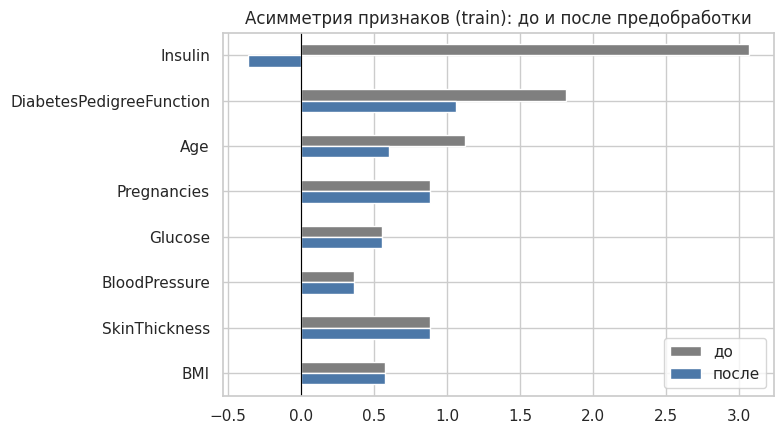

,до,после
Insulin,3.07,-0.36
DiabetesPedigreeFunction,1.81,1.06
Age,1.13,0.60
Pregnancies,0.88,0.88
Glucose,0.56,0.56
BloodPressure,0.36,0.36
SkinThickness,0.88,0.88
BMI,0.57,0.57


In [11]:
before = X_train[LOG_COLS + STD_COLS].apply(skew)
after = X_train_p[LOG_COLS + STD_COLS].apply(skew)
cmp_ = pd.DataFrame({"до": before, "после": after}).loc[LOG_COLS + STD_COLS]

ax = cmp_.plot.barh(figsize=(8, 4.5), color=["#7F7F7F", "#4C78A8"])
ax.set_title("Асимметрия признаков (train): до и после предобработки"); ax.axvline(0, color="black", lw=0.8)
ax.invert_yaxis(); plt.tight_layout(); plt.show()
cmp_.round(2)

У трёх признаков с `log1p` асимметрия заметно упала (у `Insulin` примерно с 3.1 до −0.4, у `Age` с 1.1 до 0.6, у `DiabetesPedigreeFunction` с 1.8 до 1.1). У остальных она не изменилась, как и должно быть при стандартизации: меняется масштаб, а не форма.

## 4. Проверка: что даёт предобработка (быстрый тест)

Обучим одну и ту же логистическую регрессию на сырых и на предобработанных признаках. Это не оценка качества модели (она будет на следующем этапе, без настройки и с одним разбиением), а проверка здравого смысла: предобработка не должна ухудшить результат.

In [12]:
def evaluate(Xtr, Xte):
    m = LogisticRegression(max_iter=1000, random_state=RANDOM_STATE).fit(Xtr, y_train)
    p = m.predict(Xte)
    return {"accuracy": accuracy_score(y_test, p), "precision": precision_score(y_test, p),
            "recall": recall_score(y_test, p), "F1": f1_score(y_test, p)}

res = pd.DataFrame({"сырые признаки": evaluate(X_train, X_test),
                    "после предобработки": evaluate(X_train_p, X_test_p)}).T
res.round(3)

,accuracy,precision,recall,F1
сырые признаки,0.695,0.571,0.519,0.544
после предобработки,0.695,0.574,0.500,0.535


Результат почти не изменился: accuracy одинаковая (0.695), recall 0.52 против 0.50. Это ожидаемо: логистическая регрессия на столь небольших данных не очень чувствительна к масштабу, а сам тест на 154 строках шумный (одна пациентка меняет recall примерно на 1 п.п.). Значит, польза предобработки здесь в корректности (единая шкала, меньше перекос, отсутствие утечки), а не в приросте метрик. Улучшать качество будем на этапе моделирования.

## 5. Выводы

1. **Разделение.** Данные разделены на train/test = 614/154 (80/20) со стратификацией по `Outcome`. Все параметры преобразований вычислены по train и применены к test без пересчёта, поэтому утечки нет.
2. **Масштабирование `DiabetesPedigreeFunction`.** Четыре линейных масштабирователя не меняют форму распределения (асимметрия 1.81 у всех) и не убирают выбросы, а отличаются только тем, насколько хвост влияет на шкалу: сильнее всего он «сжимает» данные у `MinMaxScaler` и `MaxAbsScaler`, слабее всего — у `RobustScaler`. Лучший итоговый вариант для этого признака — `log1p` + `StandardScaler`, потому что только логарифм уменьшает асимметрию (1.81 → 1.06).
3. **Остальные столбцы.** Правило: сильно скошенные (`Insulin`, `DiabetesPedigreeFunction`, `Age`) — `log1p` + стандартизация; примерно симметричные (`Glucose`, `BloodPressure`, `BMI`, `SkinThickness`, `Pregnancies`) — `StandardScaler`; флаги пропусков остаются без изменений. Категориальных и текстовых столбцов в данных нет.
4. **Особый случай `Insulin`.** Из-за заполнения медианой на этапе 2 у него схлопнулся IQR, поэтому `RobustScaler` для него неприменим.
5. **Ограничения.** Медианы для заполнения пропусков на этапе 2 считались по всему датасету, до разделения; в чистом виде их нужно было бы считать по train, поэтому небольшая утечка в этой части осталась. Для деревьев решений масштабирование не нужно, но не вредит. Тест логистической регрессии выполнен на одном разбиении без подбора параметров.